## **1.2 Mempelajari Penggunaan Driver Neo4J**

In [ ]:
from neo4j import GraphDatabase, RoutingControl

URL = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "UTS234nih")

#  Baris perintah berikut melakukan pembuatan sebuah Node berikut dengan relationship-nya.
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
    name=name, friend_name=friend_name, database_="neo4j", )

# Untuk mencetak dan menjalankan keseluruhan
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name", name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URL, auth=AUTH, ) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")



Unable to retrieve routing information
Transaction failed and will be retried in 1.0323939937727828s (Unable to retrieve routing information)
Unable to retrieve routing information
Transaction failed and will be retried in 2.070726260772444s (Unable to retrieve routing information)
Unable to retrieve routing information
Transaction failed and will be retried in 4.086416469670363s (Unable to retrieve routing information)
Unable to retrieve routing information
Transaction failed and will be retried in 9.507912088929618s (Unable to retrieve routing information)
Unable to retrieve routing information
Transaction failed and will be retried in 14.65136833639889s (Unable to retrieve routing information)


Guinevere
Lancelot
Merlin


**Pertanyaan Pendahuluan  (Checkpoin)**

**1. Apa nama database yang digunakan pada tutorial ini?**

Nama database yang digunakan adalah neo4j, sesuai dengan parameter database_="neo4j" pada kode Python

**2.	Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalan 1 instance!**

Selain database neo4j, kita dapat menggunakan sintaks Cypher untuk mengelola dan mengakses data, antara lain:
- DDL (Data Definition Language): CREATE, untuk membuat constraint atau index pada database.
- DML (Data Manipulation Language): CREATE, MERGE, MATCH, SET, dan DELETE untuk membuat, mencari, memperbarui, serta menghapus node dan relasi.

Untuk mengakses database lain dalam satu instance Neo4j, kita dapat menentukan nama database melalui parameter database_, misalnya database_="nama_database", selama database tersebut tersedia dan pengguna memiliki izin akses.

**3. Apa jenis graf pertemanan yang telah di buat di sini?**

Graf yang dibuat adalah graf berarah karena relasi KNOWS memiliki arah dari satu orang ke orang lainnya. Seperti:
-	Arthur -> Guinevere
-	Arthur -> Lancelot
-	Arthur -> Merlin


In [9]:
# Perintah ini akan menghapus semua node dan relationship yang ada di dalam database Neo4J.

def reset_database(driver):
    driver.execute_query(
        "MATCH (n) DETACH DELETE n", database_="neo4j", )
    print("Database reset complete.")

with GraphDatabase.driver(URL, auth=AUTH, ) as driver:
    reset_database(driver)

Database reset complete.


## **1.3 Melakukan proses Impor Data dari RetailRocket ke Database Neo4J**

#### **1. Sumber data: Roman Zykov:**
https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset

#### **2. Perhatikan fitur yang telah diunduh dengan rincian sebagai berikut:**
(a) timestamp: Waktu dalam format unix epoch.

(b) visitorid: ID unik pengunjung.

(c) event: Jenis interaksi default: view, addtocart, transaction. (d) itemid: ID unik produk.

(e) transactionid: ID transaksi, hanya terisi saat event berjenis ’transaction’.

 #### **3. Buatlah mekanisme pembuatan session Neo4J baru dengan perintah kurang lebih seperti berikut (sumber: Neo4J Driver 6.4)**

In [2]:
from neo4j import GraphDatabase, RoutingControl
URI = "bolt://localhost:7687"
AUTH = ("neo4j", "UTS234nih")

driver = GraphDatabase.driver(URI, auth=AUTH)

driver.verify_connectivity()
session = driver.session(database="neo4j")

print("Berhasil terhubung ke database Neo4j!")


Berhasil terhubung ke database Neo4j!


In [12]:

import os
import sys

# Tentukan folder tempat file events.csv berada
source = "C:/Users/lenovo/Documents/Semester 7/Graf Sains Data/UTS/uts/data from kaggle (Roman Zykov)"

# Membuat path lengkap ke events.csv
csv_file_path = os.path.join(source, "events.csv")

# Memeriksa apakah file tersedia
if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)
else:
    print(f"File ditemukan: {csv_file_path}")


File ditemukan: C:/Users/lenovo/Documents/Semester 7/Graf Sains Data/UTS/uts/data from kaggle (Roman Zykov)\events.csv


In [ ]:
import pandas as pd
data = pd.read_csv(csv_file_path)
data.head()

,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [17]:
data.shape

(2756101, 5)

In [18]:
data['event'].value_counts()

event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64

#### **4. Anda lanjutkan dengan proses impor dengan mekanisme batch, kurang lebih sebagai berikut**

In [14]:

import pandas as pd
from tqdm import tqdm

# ==================================================
# 1. MEMBUAT CONSTRAINT
# ==================================================
def create_constraints(session):
    session.run("""
        CREATE CONSTRAINT visitor_id_uniq IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorId IS UNIQUE
    """)

    session.run("""
        CREATE CONSTRAINT item_id_uniq IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemId IS UNIQUE
    """)

    print("Constraints berhasil dibuat.")


# ==================================================
# 2. FUNGSI IMPOR SETIAP BATCH
# ==================================================
def import_batch(tx, records):
    query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row
        WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        RETURN 1 AS imported

        UNION ALL

        WITH v, i, row
        WITH v, i, row
        WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        RETURN 1 AS imported

        UNION ALL

        WITH v, i, row
        WITH v, i, row
        WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)
        RETURN 1 AS imported
    }
    RETURN count(imported) AS total_imported
    """

    tx.run(query, batch=records).consume()


# ==================================================
# 3. PROSES IMPOR DATASET PER BATCH
# ==================================================
batch_size = 2000

with driver.session(database="neo4j") as session:

    # Membuat constraint
    print("Membuat constraints...")
    create_constraints(session)

    # Menghitung jumlah baris CSV
    print(f"Membaca file: {csv_file_path}")

    with open(csv_file_path, encoding="utf-8") as f:
        total_rows = sum(1 for _ in f) - 1

    total_chunks = (total_rows + batch_size - 1) // batch_size

    # Membaca CSV secara bertahap
    chunks = pd.read_csv(
        csv_file_path,
        chunksize=batch_size
    )

    print("Memulai proses impor ke Neo4j...")

    for chunk in tqdm(
        chunks,
        total=total_chunks,
        desc="Mengimpor batch data"
    ):
        # Membersihkan tipe data
        chunk["transactionid"] = (
            chunk["transactionid"]
            .fillna("")
            .astype(str)
        )

        chunk["visitorid"] = chunk["visitorid"].astype(int)
        chunk["itemid"] = chunk["itemid"].astype(int)
        chunk["timestamp"] = chunk["timestamp"].astype(int)

        # Mengubah DataFrame menjadi list of dictionaries
        records = chunk.to_dict(orient="records")

        # Impor batch ke Neo4j
        session.execute_write(import_batch, records)

print("Proses impor selesai!")


Membuat constraints...
Constraints berhasil dibuat.
Membaca file: C:/Users/lenovo/Documents/Semester 7/Graf Sains Data/UTS/uts/data from kaggle (Roman Zykov)\events.csv
Memulai proses impor ke Neo4j...


Mengimpor batch data: 100%|██████████| 1379/1379 [09:09<00:00,  2.51it/s]

Proses impor selesai!


In [15]:

with driver.session(database="neo4j") as session:

    result = session.run("""
        MATCH (n:Visitor)
        RETURN count(n) AS total_visitor
    """)
    print("Total Visitor:", result.single()["total_visitor"])

    result = session.run("""
        MATCH (n:Item)
        RETURN count(n) AS total_item
    """)
    print("Total Item:", result.single()["total_item"])

    result = session.run("""
        MATCH (:Visitor)-[r]->(:Item)
        RETURN type(r) AS jenis_relasi, count(r) AS jumlah
        ORDER BY jenis_relasi
    """)

    print("\nJumlah relasi:")
    for record in result:
        print(record["jenis_relasi"], ":", record["jumlah"])


Total Visitor: 1407580
Total Item: 235061

Jumlah relasi:
ADDED_TO_CART : 69332
BOUGHT : 22457
VIEWED : 2664312


In [19]:

# Periksa jumlah item unik dari CSV
df_items = pd.read_csv(
    csv_file_path,
    usecols=["itemid"]
)

unique_items_csv = df_items["itemid"].nunique()

# Periksa jumlah node Item di Neo4j
with driver.session(database="neo4j") as session:
    result = session.run("""
        MATCH (i:Item)
        RETURN count(i) AS total_item
    """)
    unique_items_neo4j = result.single()["total_item"]

print("Item unik di CSV :", unique_items_csv)
print("Node Item Neo4j  :", unique_items_neo4j)

if unique_items_csv == unique_items_neo4j:
    print("VALID: Jumlah item unik sesuai.")
else:
    print("PERLU DIPERIKSA: Jumlah item berbeda.")


Item unik di CSV : 235061
Node Item Neo4j  : 235061
VALID: Jumlah item unik sesuai.


# **Soal UTS**

### **2.1 Wrangling dan EDA (Maks. skor: 45)**

##### **1. Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yang dipilih tiap mahasiswa tidak boleh sama! (akan ditentukan)** Misal: Fold training (P1) → 01/2023 - 03/2023; Fold testing (P2) 01/2024 - 06/2024.**

Filter Data
- P1 --> 02/06/2015 sampai 21/08/2015
- P2 --> 22/08/2015 sampai 11/09/2015

In [5]:
import pandas as pd
import os

df = pd.read_csv("data from kaggle (Roman Zykov)/events.csv")
# 3. Konversi timestamp Unix (milidetik) menjadi datetime UTC
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)

p1_start = pd.Timestamp("2015-06-02 00:00:00", tz="UTC")
p1_end   = pd.Timestamp("2015-08-22 00:00:00", tz="UTC")

p2_start = pd.Timestamp("2015-08-22 00:00:00", tz="UTC")
p2_end   = pd.Timestamp("2015-09-12 00:00:00", tz="UTC")

df_p1 = df[(df["datetime"] >= p1_start) & (df["datetime"] < p1_end)].copy()
df_p2 = df[(df["datetime"] >= p2_start) & (df["datetime"] < p2_end)].copy()

In [6]:
print("Data Awal\n--------------------")
print("Jumlah baris:", len(df))
print("Tanggal paling awal:", df["datetime"].min())
print("Tanggal paling akhir:", df["datetime"].max())

Data Awal
--------------------
Jumlah baris: 2756101
Tanggal paling awal: 2015-05-03 03:00:04.384000+00:00
Tanggal paling akhir: 2015-09-18 02:59:47.788000+00:00


##### **2. Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!**

In [7]:
print("Data Hasil filter P1\n--------------------")
print("Jumlah baris:", len(df_p1))
print("Tanggal paling awal:", df_p1["datetime"].min())
print("Tanggal paling akhir:", df_p1["datetime"].max())

print("\n=======================================================\nData Hasil filter P2\n--------------------")
print("Jumlah baris:", len(df_p2))
print("Tanggal paling awal:", df_p2["datetime"].min())
print("Tanggal paling akhir:", df_p2["datetime"].max())

print("\n\n Total baris setelah filter P1 dan P2:", len(df_p1) + len(df_p2))

Data Hasil filter P1
--------------------
Jumlah baris: 1664244
Tanggal paling awal: 2015-06-02 00:00:01.197000+00:00
Tanggal paling akhir: 2015-08-21 23:59:59.243000+00:00

Data Hasil filter P2
--------------------
Jumlah baris: 381563
Tanggal paling awal: 2015-08-22 00:00:02.163000+00:00
Tanggal paling akhir: 2015-09-11 23:59:51.336000+00:00


 Total baris setelah filter P1 dan P2: 2045807


In [8]:
df_p1.drop(columns=["datetime"]).to_csv("P1_training.csv",index=False)
df_p2.drop(columns=["datetime"]).to_csv("P2_testing.csv",index=False)

print("\nFile berhasil disimpan:")



File berhasil disimpan:


#### **3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!**

**- untuk menghitung komposisi subgraph periode P1**

In [9]:
p1_start = int(pd.Timestamp("2015-06-02 00:00:00", tz="UTC").timestamp() * 1000)
p1_end = int(pd.Timestamp("2015-08-22 00:00:00", tz="UTC").timestamp() * 1000)


query_komposisi = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $p1_start
  AND r.timestamp < $p1_end
RETURN
    count(DISTINCT v) AS jumlah_visitor,
    count(DISTINCT i) AS jumlah_item,
    count(r) AS jumlah_interaksi
"""

records, summary, keys = driver.execute_query(
    query_komposisi,
    p1_start=p1_start,
    p1_end=p1_end,
    database_="neo4j"
)

df_komposisi = pd.DataFrame([record.data() for record in records])
display(df_komposisi)

,jumlah_visitor,jumlah_item,jumlah_interaksi
0,865191,190020,1664244


menghitung jenis relasi yang terdapat dalam subgraph

In [10]:
query_relasi = """
MATCH (:Visitor)-[r]->(:Item)
WHERE r.timestamp >= $p1_start
  AND r.timestamp < $p1_end
RETURN type(r) AS jenis_interaksi, count(r) AS jumlah
ORDER BY jumlah DESC
"""

records, summary, keys = driver.execute_query(
    query_relasi,
    p1_start=p1_start,
    p1_end=p1_end,
    database_="neo4j"
)

df_relasi = pd.DataFrame([record.data() for record in records])
display(df_relasi)

,jenis_interaksi,jumlah
0,VIEWED,1608441
1,ADDED_TO_CART,42020
2,BOUGHT,13783


####  **4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!**

In [12]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix

# 1. Membaca data periode P1
df_p1 = pd.read_csv("P1_training.csv")

# 2. Mengambil pasangan User dan Item yang unik
df_interaksi = df_p1[["visitorid", "itemid"]].drop_duplicates()

# 3. Membuat pemetaan ID User dan Item menjadi indeks
user_ids = df_interaksi["visitorid"].unique()
item_ids = df_interaksi["itemid"].unique()

user_to_idx = {user: idx for idx, user in enumerate(user_ids)}
item_to_idx = {item: idx for idx, item in enumerate(item_ids)}

rows = df_interaksi["visitorid"].map(user_to_idx).to_numpy()
cols = df_interaksi["itemid"].map(item_to_idx).to_numpy()

# 4. Membentuk sparse matrix VSM biner
vsm_user = csr_matrix(
    (
        np.ones(len(df_interaksi), dtype=np.uint8),
        (rows, cols)
    ),
    shape=(len(user_ids), len(item_ids))
)

# 5. Menampilkan karakteristik VSM
print("Jumlah User:", len(user_ids))
print("Jumlah Item:", len(item_ids))
print("Shape VSM:", vsm_user.shape)
print("Dimensi vektor setiap User:", vsm_user.shape[1])
print("Jumlah pasangan User-Item:", vsm_user.nnz)

total_elemen = vsm_user.shape[0] * vsm_user.shape[1]
sparsity = 1 - (vsm_user.nnz / total_elemen)

print(f"Sparsity: {sparsity:.6%}")

Jumlah User: 865191
Jumlah Item: 190020
Shape VSM: (865191, 190020)
Dimensi vektor setiap User: 190020
Jumlah pasangan User-Item: 1298734
Sparsity: 99.999210%


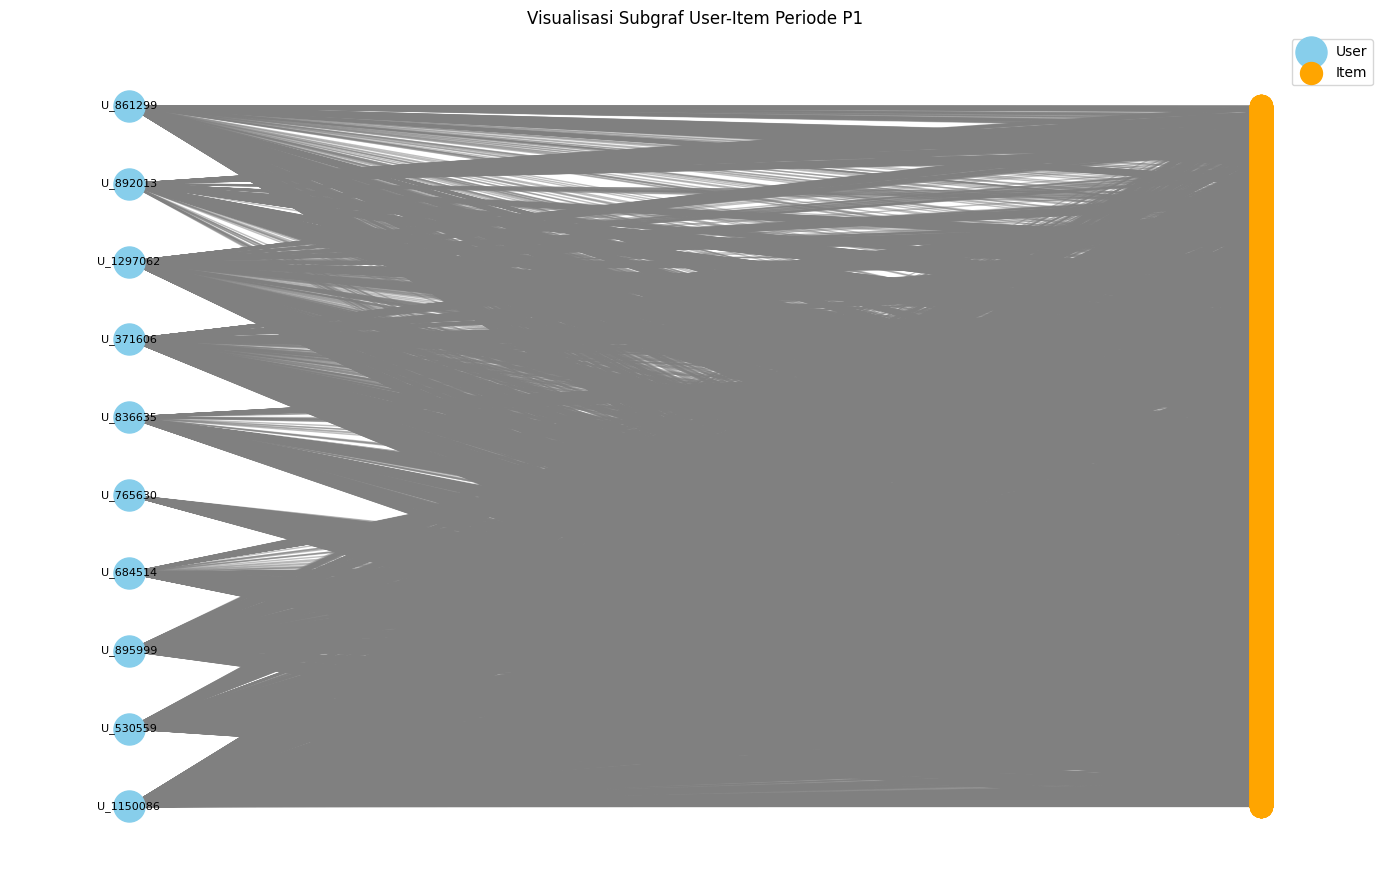

Jumlah node pada graf visualisasi: 10051
Jumlah edge pada graf visualisasi: 14342


In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

user_degree = df_interaksi["visitorid"].value_counts()
selected_users = user_degree.head(10).index

df_plot = df_interaksi[df_interaksi["visitorid"].isin(selected_users)].copy()

# 7. Membuat graf bipartit User-Item
G = nx.Graph()

for _, row in df_plot.iterrows():
    user = f"U_{row['visitorid']}"
    item = f"I_{row['itemid']}"

    G.add_node(user, bipartite="user")
    G.add_node(item, bipartite="item")
    G.add_edge(user, item)

# 8. Menentukan posisi node berdasarkan kelompoknya
users_plot = [n for n, d in G.nodes(data=True)if d["bipartite"] == "user"]
items_plot = [n for n, d in G.nodes(data=True)if d["bipartite"] == "item"]

pos = nx.bipartite_layout(G, users_plot)

# 9. Menampilkan graf
plt.figure(figsize=(14, 9))

nx.draw_networkx_nodes(G, pos, nodelist=users_plot, node_color="skyblue", node_size=500, label="User")
nx.draw_networkx_nodes(G, pos,nodelist=items_plot,node_color="orange",node_size=250,label="Item")
nx.draw_networkx_edges(G, pos,edge_color="gray",alpha=0.5)
nx.draw_networkx_labels(G, pos,labels={n: n for n in users_plot},font_size=8)

plt.title("Visualisasi Subgraf User-Item Periode P1")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah node pada graf visualisasi:", G.number_of_nodes())
print("Jumlah edge pada graf visualisasi:", G.number_of_edges())


In [ ]:
interaksi_per_user = np.asarray(vsm_user.sum(axis=1)).ravel()

print("Jumlah User dengan minimal satu interaksi:", vsm_user.shape[0])
print("Jumlah Item:", vsm_user.shape[1])
print("Jumlah pasangan User-Item:", vsm_user.nnz)

print("Rata-rata Item per User:",round(interaksi_per_user.mean(), 2))
print("Interaksi minimum per User:",interaksi_per_user.min())
print("Interaksi maksimum per User:",interaksi_per_user.max())

Jumlah User dengan minimal satu interaksi: 865191
Jumlah Item: 190020
Jumlah pasangan User-Item: 1298734
Rata-rata Item per User: 1.5
Interaksi minimum per User: 1
Interaksi maksimum per User: 3328


#### **5.	Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!**

In [16]:

import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix

# 1. Membaca data periode P1
df_p1 = pd.read_csv("P1_training.csv")

# 2. Mengambil pasangan User-Item yang unik
df_interaksi = df_p1[["visitorid", "itemid"]].drop_duplicates()

# 3. Membuat pemetaan ID Item dan User menjadi indeks
item_ids = df_interaksi["itemid"].unique()
user_ids = df_interaksi["visitorid"].unique()

item_to_idx = {item: idx for idx, item in enumerate(item_ids)}
user_to_idx = {user: idx for idx, user in enumerate(user_ids)}

rows = df_interaksi["itemid"].map(item_to_idx).to_numpy()
cols = df_interaksi["visitorid"].map(user_to_idx).to_numpy()

# 4. Membentuk sparse matrix VSM Item
vsm_item = csr_matrix(
    (
        np.ones(len(df_interaksi), dtype=np.uint8),
        (rows, cols)
    ),
    shape=(len(item_ids), len(user_ids))
)

# 5. Menampilkan karakteristik VSM
print("Jumlah Item:", len(item_ids))
print("Jumlah User:", len(user_ids))
print("Shape VSM:", vsm_item.shape)
print("Dimensi vektor setiap Item:", vsm_item.shape[1])
print("Jumlah pasangan Item-User:", vsm_item.nnz)

total_elemen = vsm_item.shape[0] * vsm_item.shape[1]
sparsity = 1 - (vsm_item.nnz / total_elemen)

print(f"Sparsity: {sparsity:.6%}")

# 6. Menghitung jumlah User unik yang berinteraksi dengan setiap Item
user_per_item = np.asarray(vsm_item.sum(axis=1)).ravel()

print("Rata-rata User per Item:", round(user_per_item.mean(), 2))
print("Jumlah User minimum per Item:", user_per_item.min())
print("Jumlah User maksimum per Item:", user_per_item.max())


Jumlah Item: 190020
Jumlah User: 865191
Shape VSM: (190020, 865191)
Dimensi vektor setiap Item: 865191
Jumlah pasangan Item-User: 1298734
Sparsity: 99.999210%
Rata-rata User per Item: 6.83
Jumlah User minimum per Item: 1
Jumlah User maksimum per Item: 1851


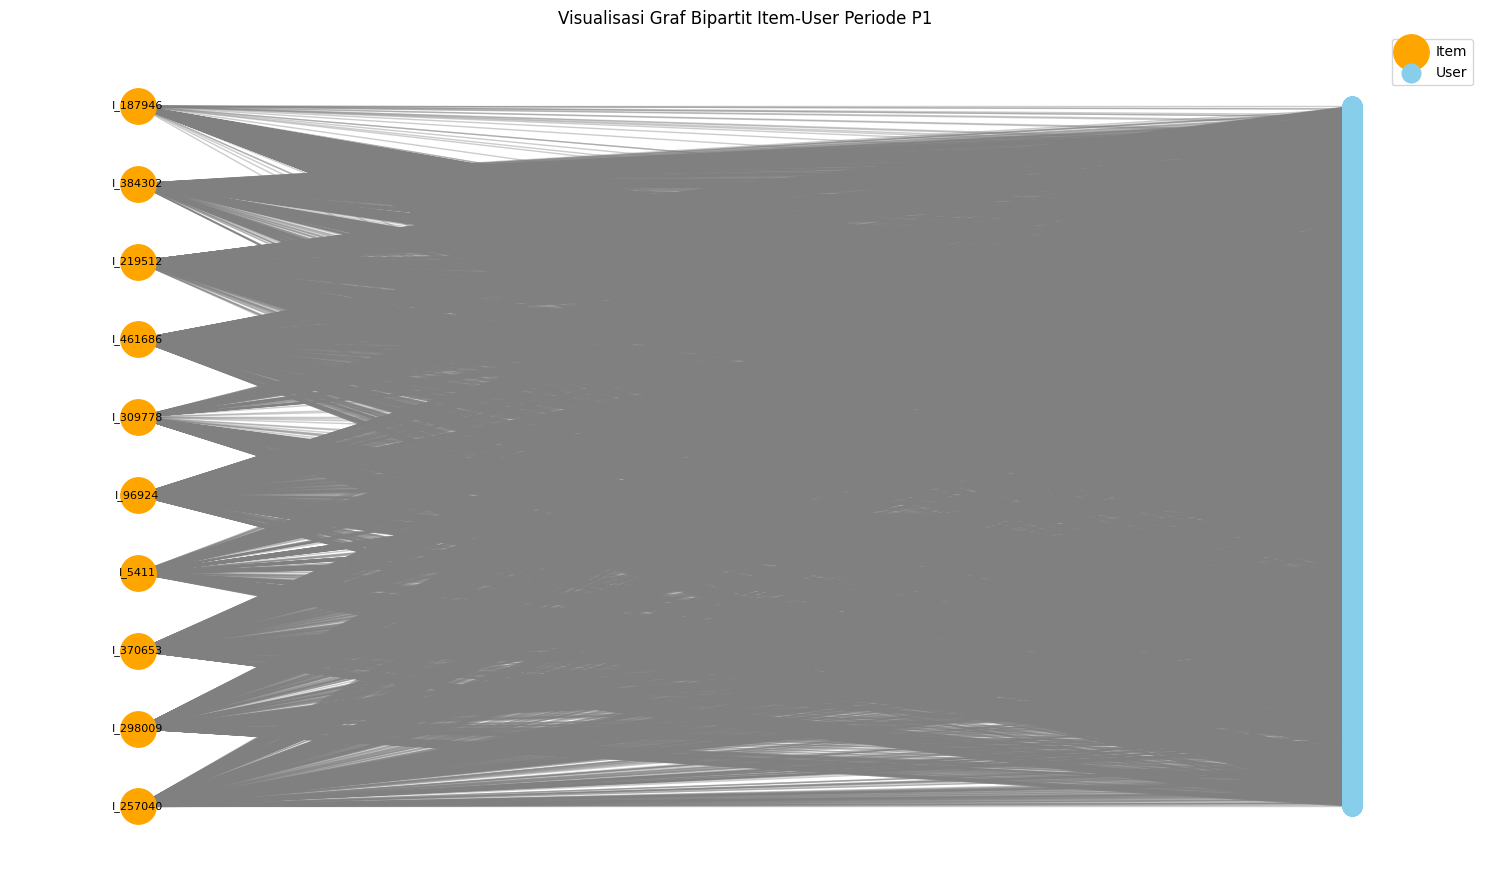

Jumlah node pada graf visualisasi: 9612
Jumlah edge pada graf visualisasi: 9956
Jumlah Item yang divisualisasikan: 10


In [17]:

import networkx as nx
import matplotlib.pyplot as plt

# 1. Memilih 10 Item dengan User unik terbanyak
item_degree = df_interaksi["itemid"].value_counts()
selected_items = item_degree.head(10).index

# 2. Mengambil interaksi dari Item terpilih
df_plot = df_interaksi[
    df_interaksi["itemid"].isin(selected_items)
].copy()

# 3. Membentuk graf bipartit Item-User
G_item = nx.Graph()

for _, row in df_plot.iterrows():
    item = f"I_{row['itemid']}"
    user = f"U_{row['visitorid']}"

    G_item.add_node(item, bipartite="item")
    G_item.add_node(user, bipartite="user")
    G_item.add_edge(item, user)

# 4. Memisahkan jenis node
items_plot = [
    n for n, d in G_item.nodes(data=True)
    if d["bipartite"] == "item"
]

users_plot = [
    n for n, d in G_item.nodes(data=True)
    if d["bipartite"] == "user"
]

# 5. Menentukan posisi node
pos = nx.bipartite_layout(G_item, items_plot)

# 6. Menggambar graf
plt.figure(figsize=(15, 9))

nx.draw_networkx_nodes(
    G_item, pos,
    nodelist=items_plot,
    node_color="orange",
    node_size=650,
    label="Item"
)

nx.draw_networkx_nodes(
    G_item, pos,
    nodelist=users_plot,
    node_color="skyblue",
    node_size=180,
    label="User"
)

nx.draw_networkx_edges(
    G_item, pos,
    edge_color="gray",
    alpha=0.4
)

# Label hanya untuk Item agar gambar tidak terlalu padat
item_labels = {n: n for n in items_plot}
nx.draw_networkx_labels(
    G_item, pos,
    labels=item_labels,
    font_size=8
)

plt.title("Visualisasi Graf Bipartit Item-User Periode P1")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah node pada graf visualisasi:", G_item.number_of_nodes())
print("Jumlah edge pada graf visualisasi:", G_item.number_of_edges())
print("Jumlah Item yang divisualisasikan:", len(items_plot))


### **2.2 Analytics (Maks. skor: 55)**

In [40]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors

# Membaca data
df_p1 = pd.read_csv("P1_training.csv")
df_p2 = pd.read_csv("P2_testing.csv")

# Mengambil pasangan user-item yang unik dari P1
interaksi_p1 = df_p1[["visitorid", "itemid"]].drop_duplicates()

# Mengambil pasangan user-item yang unik dari P2
interaksi_p2 = df_p2[["visitorid", "itemid"]].drop_duplicates()

# Memilih user yang memiliki interaksi di P1 dan P2
user_p1 = set(interaksi_p1["visitorid"].unique())
user_p2 = set(interaksi_p2["visitorid"].unique())
user_eligible = sorted(user_p1.intersection(user_p2))

print("Jumlah user P1:", len(user_p1))
print("Jumlah user P2:", len(user_p2))
print("Jumlah user yang dapat dievaluasi:", len(user_eligible))

Jumlah user P1: 865191
Jumlah user P2: 216097
Jumlah user yang dapat dievaluasi: 17251


In [ ]:
user_ids = interaksi_p1["visitorid"].unique()
item_ids = interaksi_p1["itemid"].unique()

user_to_idx = {u: i for i, u in enumerate(user_ids)}
item_to_idx = {item: i for i, item in enumerate(item_ids)}

rows = interaksi_p1["itemid"].map(item_to_idx).to_numpy()
cols = interaksi_p1["visitorid"].map(user_to_idx).to_numpy()

vsm_item = csr_matrix(
    (np.ones(len(interaksi_p1)), (rows, cols)),
    shape=(len(item_ids), len(user_ids))
)

print("Shape matriks Item-User:", vsm_item.shape)
print("Jumlah interaksi unik:", vsm_item.nnz)

knn = NearestNeighbors(
    n_neighbors=6,       
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

knn.fit(vsm_item)

print("Model Item-Based KNN berhasil dilatih.")
print("Parameter k tetangga:", 5)

Shape matriks Item-User: (190020, 865191)
Jumlah interaksi unik: 1298734
Model Item-Based KNN berhasil dilatih.
Parameter k tetangga: 5


In [ ]:
# Pemilihan user secara acak yang dapat direproduksi
rng = np.random.default_rng(40)
user_target = rng.choice(user_eligible)

print("User yang dipilih:", user_target)
item_user = set(
    interaksi_p1.loc[
        interaksi_p1["visitorid"] == user_target, "itemid"
    ]
)

skor_kandidat = {}

for item in item_user:
    idx_item = item_to_idx[item]

    distances, indices = knn.kneighbors(
        vsm_item[idx_item],
        n_neighbors=6
    )

    for distance, idx_tetangga in zip(distances[0], indices[0]):
        item_tetangga = item_ids[idx_tetangga]

        if item_tetangga == item or item_tetangga in item_user:
            continue

        similarity = 1 - distance

        skor_kandidat[item_tetangga] = max(
            skor_kandidat.get(item_tetangga, 0),
            float(similarity)
        )

peringkat = sorted(
    skor_kandidat.items(),
    key=lambda x: (-x[1], x[0])
)

top5 = peringkat[:5]
top3 = peringkat[:3]

print("\n=== TIGA ITEM REKOMENDASI ===")
for urutan, (item, skor) in enumerate(top3, start=1):
    print(f"{urutan}. Item {item} | Similarity = {skor:.6f}")

print("\nJumlah rekomendasi yang ditampilkan:", len(top3))

User yang dipilih: 797182

=== TIGA ITEM REKOMENDASI ===
1. Item 318475 | Similarity = 0.176777
2. Item 420628 | Similarity = 0.144338
3. Item 251632 | Similarity = 0.111803

Jumlah rekomendasi yang ditampilkan: 3


2A

In [ ]:
item_relevan = set(interaksi_p2.loc[interaksi_p2["visitorid"] == user_target, "itemid"])

rekomendasi_5 = [item for item, skor in top5]
relevansi_5 = [int(item in item_relevan)for item in rekomendasi_5]

hit_at_5 = int(any(relevansi_5))

print("User yang dievaluasi:", user_target)
print("Top 5 rekomendasi:", rekomendasi_5)
print("Jumlah item relevan pada P2:", len(item_relevan))
print("Relevansi Top 5:", relevansi_5)
print("Hit@5:", hit_at_5)

User yang dievaluasi: 797182
Top 5 rekomendasi: [np.int64(318475), np.int64(420628), np.int64(251632), np.int64(330794), np.int64(189681)]
Jumlah item relevan pada P2: 1
Relevansi Top 5: [0, 0, 0, 0, 0]
Hit@5: 0


2B

In [ ]:
dcg_at_5 = sum(rel / np.log2(posisi + 2)for posisi, rel in enumerate(relevansi_5))
jumlah_relevan_top5_maks = min(len(item_relevan), 5)

idcg_at_5 = sum(
    1 / np.log2(posisi + 2)
    for posisi in range(jumlah_relevan_top5_maks)
)

if idcg_at_5 > 0:
    ndcg_at_5 = dcg_at_5 / idcg_at_5
else:
    ndcg_at_5 = np.nan

print("Relevansi Top 5:", relevansi_5)
print(f"DCG@5: {dcg_at_5:.4f}")
print(f"IDCG@5: {idcg_at_5:.4f}")

if np.isnan(ndcg_at_5):
    print("NDCG@5: Tidak dapat dievaluasi (tidak ada item relevan pada P2)")
else:
    print(f"NDCG@5: {ndcg_at_5:.4f}")

Relevansi Top 5: [0, 0, 0, 0, 0]
DCG@5: 0.0000
IDCG@5: 1.0000
NDCG@5: 0.0000
